
# Module 25: DBSCAN & Hierarchical Clustering

This notebook is designed for hands-on practice.



## Dataset 1: Blob Dataset with Different Densities

This dataset contains clusters with different densities.
DBSCAN should behave differently for each cluster.


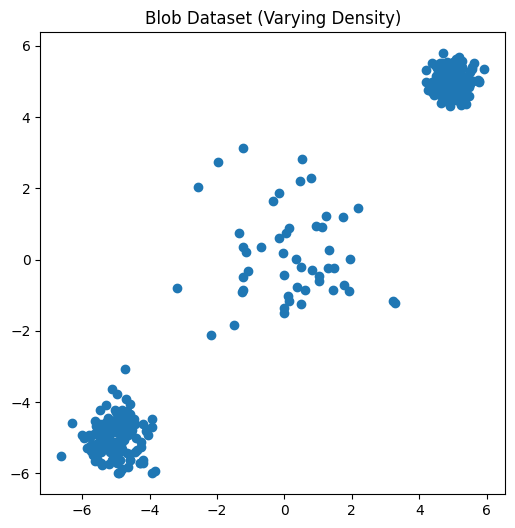

In [1]:
#Done for you
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

X_blobs, _ = make_blobs(
    n_samples=[150, 50, 200],
    centers=[(-5, -5), (0, 0), (5, 5)],
    cluster_std=[0.5, 1.5, 0.3],
    random_state=42
)

plt.figure(figsize=(6,6))
plt.scatter(X_blobs[:,0], X_blobs[:,1])
plt.title("Blob Dataset (Varying Density)")
plt.show()


### TODO 1: Scaling

Scale the dataset using StandardScaler.

Think:
- Why is scaling important here?
- What happens if we skip scaling?


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs
import pandas as pd

# Ensure data is generated if kernel was restarted

# TODO: Scale the dataset and verify that the mean is ~0 and variance is ~1

scaler = StandardScaler()

X_blobs_scaled = scaler.fit_transform(X_blobs)

# Challenge: Check the summary statistics of the scaled data
pd.DataFrame(X_blobs_scaled).describe()

,0,1
count,4.000000e+02,4.000000e+02
mean,5.773160e-17,-6.439294e-17
std,1.001252e+00,1.001252e+00
min,-1.552926e+00,-1.423594e+00
25%,-1.172044e+00,-1.159617e+00
50%,6.645817e-01,6.608559e-01
75%,9.330801e-01,9.311268e-01
max,1.132521e+00,1.103948e+00



### TODO 2: DBSCAN on Blob Dataset

Apply DBSCAN.
Experiment with different values of eps and min_samples.


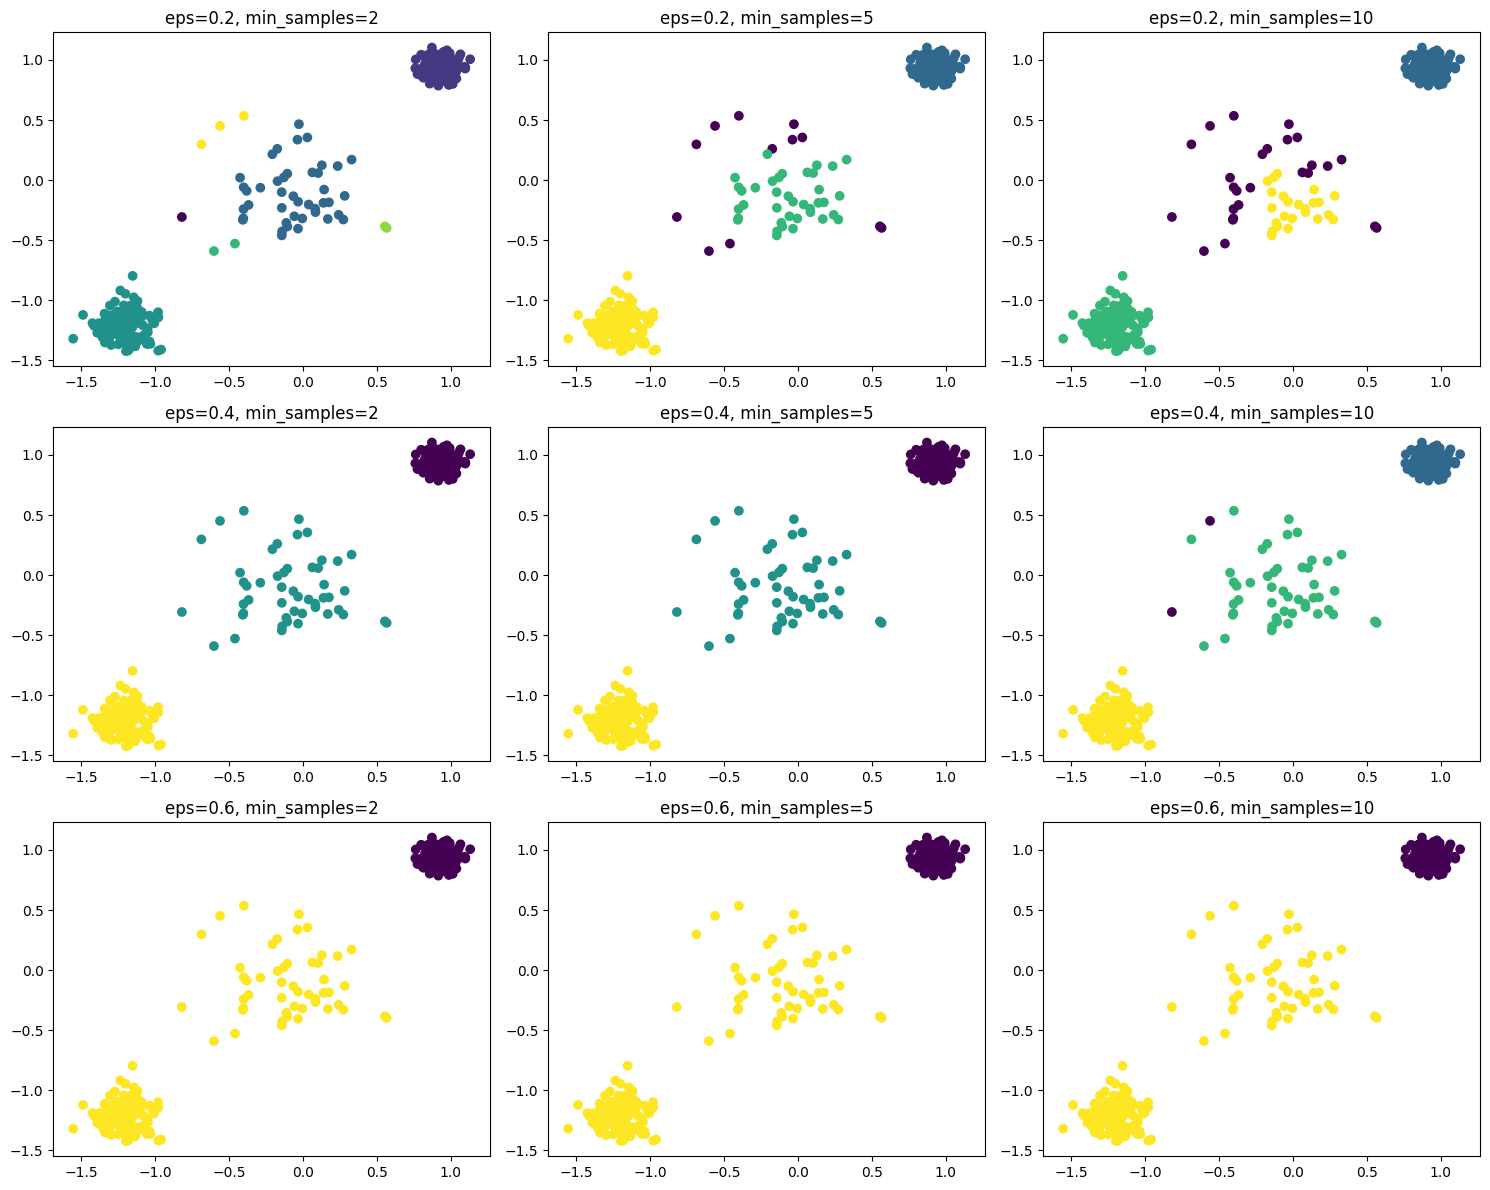

In [5]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import numpy as np

# TODO: Implement DBSCAN
# Challenge: Create a function that loops through a grid of eps [0.2, 0.4, 0.6]
# and min_samples [2, 5, 10] and plots the results in a 3x3 subplot grid.

def plot_dbscan_grid( X_blobs_scaled ) :
  eps_values = [0.2, 0.4, 0.6]
  min_samples_values = [2, 5, 10]

  fig, axes = plt.subplots( 3, 3, figsize = (15, 12) )

  for i, eps in enumerate( eps_values ) :
    for j, min_samples in enumerate( min_samples_values ) :

      dbscan = DBSCAN(
          eps = eps,
          min_samples = min_samples
      )

      labels = dbscan.fit_predict( X_blobs_scaled )

      axes[i, j].scatter(
          X_blobs_scaled[:, 0],
          X_blobs_scaled[:, 1],
          c = labels,
          cmap = "viridis"
      )

      axes[i, j].set_title(
          f"eps={eps}, min_samples={min_samples}"
      )


  plt.tight_layout()
  plt.show()

plot_dbscan_grid(X_blobs_scaled)


### TODO 3: k-Distance Plot

Use a k-distance plot to estimate eps.


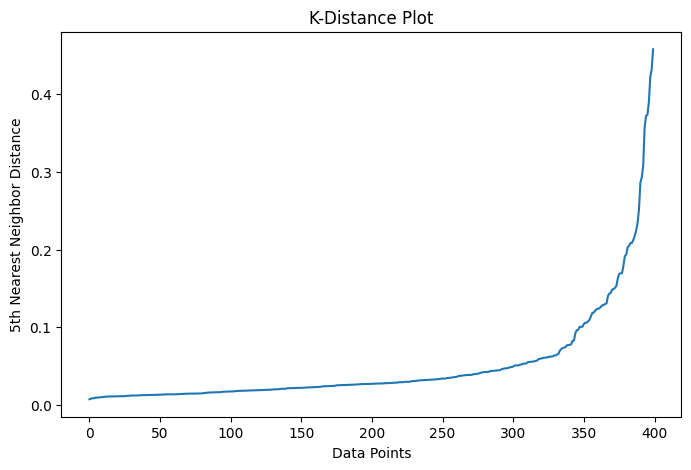

In [6]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np

# TODO: Create k-distance plot
# Challenge: Use the 'knee' point detection logic.
# Calculate distances to the 5th nearest neighbor, sort them, and plot.

neighbors = NearestNeighbors(
    n_neighbors = 5
)

neighbors_fit = neighbors.fit(X_blobs_scaled)

distances, indices = neighbors_fit.kneighbors(X_blobs_scaled)

distances = np.sort(distances[:, 4])

plt.figure(figsize = (8, 5))
plt.plot(distances)
plt.xlabel("Data Points")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Plot")
plt.show()



## Dataset 2: Circular Dataset

This dataset contains non-linear circular clusters.


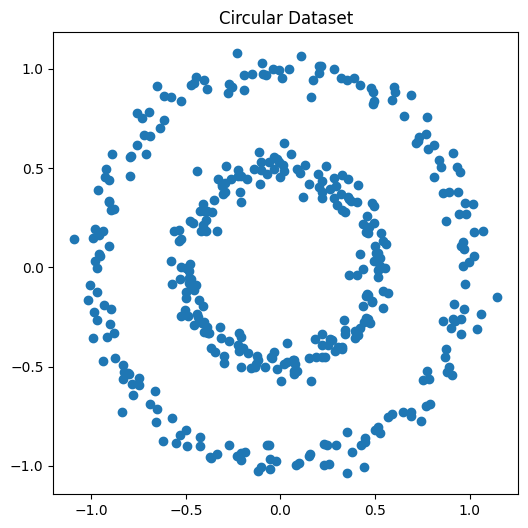

In [7]:
#Done for you
from sklearn.datasets import make_circles

X_circles, _ = make_circles(
    n_samples=400,
    factor=0.5,
    noise=0.05,
    random_state=42
)

plt.figure(figsize=(6,6))
plt.scatter(X_circles[:,0], X_circles[:,1])
plt.title("Circular Dataset")
plt.show()


### TODO 4: DBSCAN on Circular Data

Apply DBSCAN and observe cluster shape.


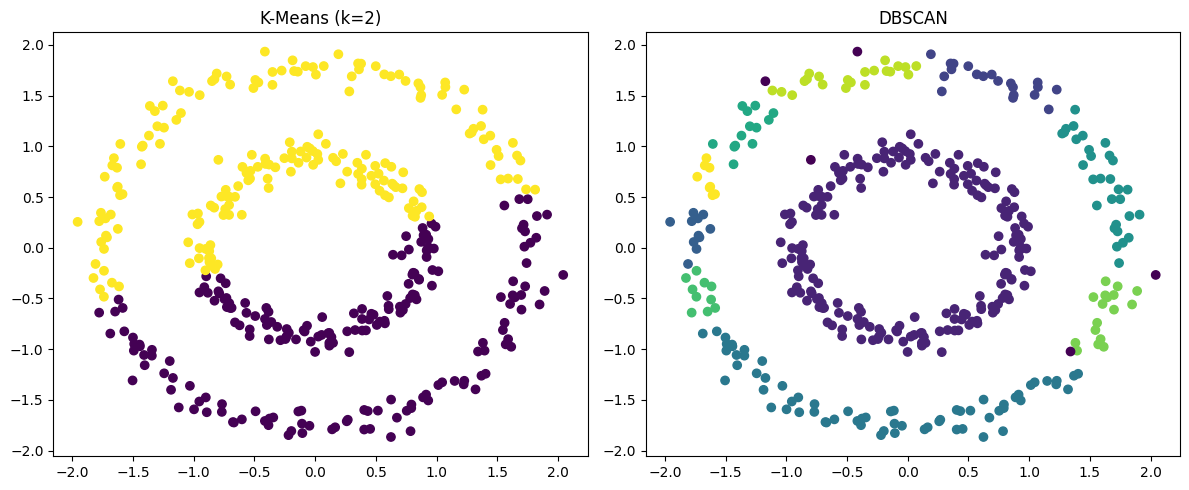

In [20]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_circles
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Ensure data is generated

# TODO: Compare DBSCAN results side-by-side with K-Means (k=2)

# X_circles

scaler = StandardScaler()

X_circles_scaled = scaler.fit_transform(X_circles)

# KMeans (Expect failure for non-convex shapes)

kmeans = KMeans(
    n_clusters = 2,
    random_state = 42
)

kmeans_label = kmeans.fit_predict(X_circles_scaled)

dbscan = DBSCAN(
    eps = 0.2,
    min_samples = 5
)

dbscan_label = dbscan.fit_predict(X_circles_scaled)


# DBSCAN (Expect success for dense regions)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_circles_scaled[:, 0],
    X_circles_scaled[:, 1],
    c=kmeans_label,
    cmap="viridis"
)
axes[0].set_title("K-Means (k=2)")

axes[1].scatter(
    X_circles_scaled[:, 0],
    X_circles_scaled[:, 1],
    c=dbscan_label,
    cmap="viridis"
)
axes[1].set_title("DBSCAN")

plt.tight_layout()
plt.show()


## Hierarchical Clustering Practice



### TODO 5: Agglomerative Clustering

Try different linkage methods:
single, complete, average, ward


In [21]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

# TODO: Apply hierarchical clustering
# Challenge: For each linkage method, calculate the Silhouette Score.

linkage_methods = ["ward", "complete", "average", "single"]

for linkage in linkage_methods:

    # Apply Hierarchical Clustering
    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=linkage
    )

    labels = model.fit_predict(X_blobs_scaled)

    # Calculate Silhouette Score
    score = silhouette_score(X_blobs_scaled, labels)

    print(f"{linkage.capitalize()} Linkage: {score:.4f}")


Ward Linkage: 0.8681
Complete Linkage: 0.8681
Average Linkage: 0.8681
Single Linkage: 0.8681



### TODO 6: Dendrogram

Create a dendrogram using Ward linkage.


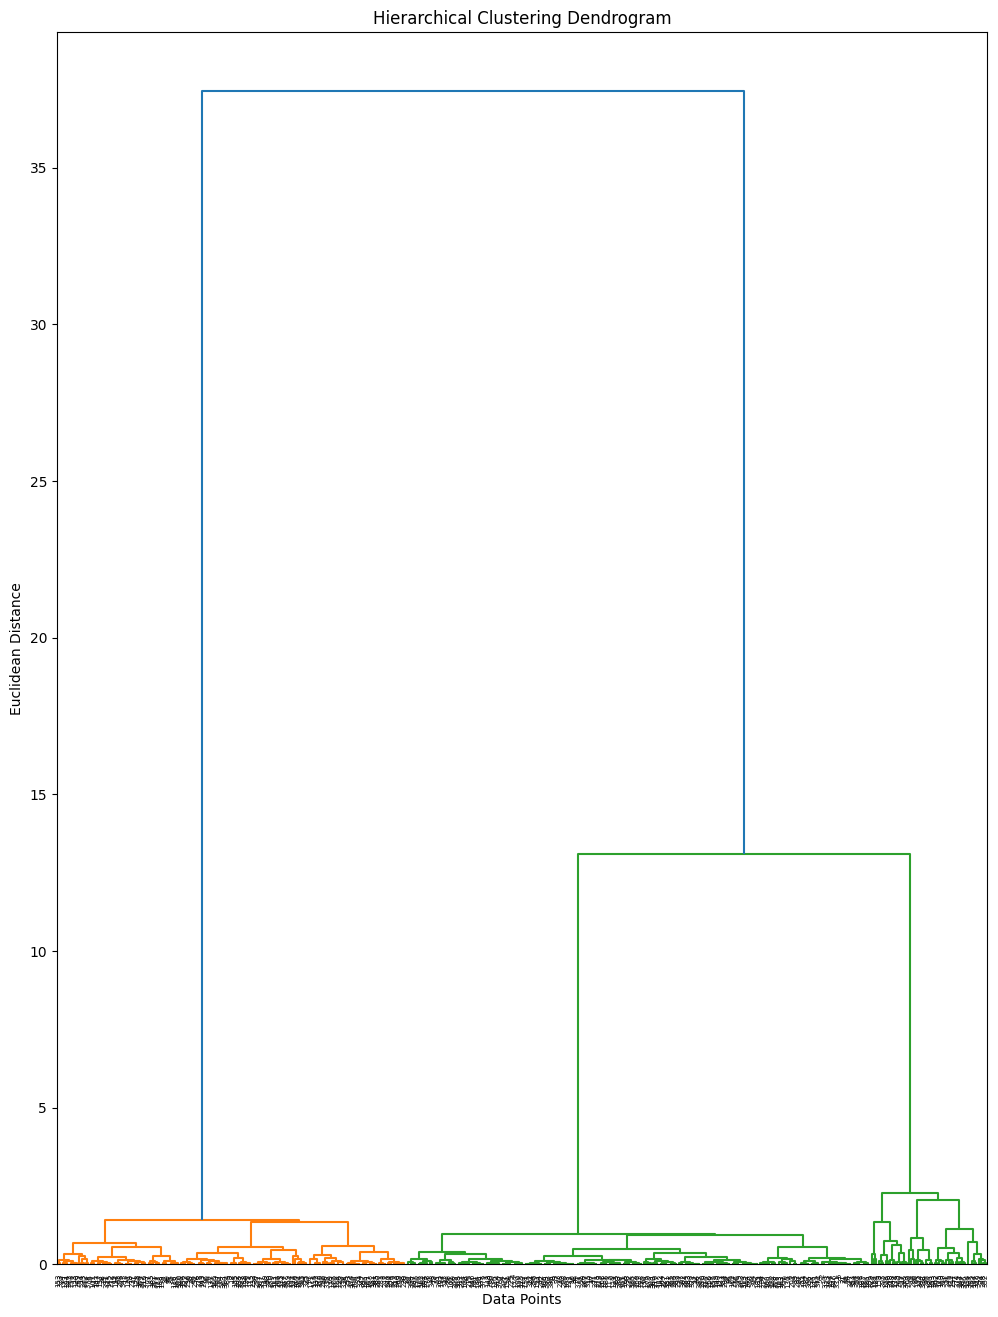

In [27]:
from scipy.cluster.hierarchy import dendrogram, linkage

# TODO: Create dendrogram here

# Create the linkage matrix
linked = linkage(X_blobs_scaled, method="ward")

# Plot the dendrogram
plt.figure(figsize=(12, 16))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")

plt.show()

## The Grand Challenge: 3D Density Optimization

In this final, hard challenge, we will step into 3D space and automate our parameter selection.

### Requirements:
1. **Generate 3D Data**: Use `make_blobs` to create 1000 samples in 3D space with varying standard deviations.
2. **Parameter Grid Search**: Write a loop that tests `eps` from 0.1 to 1.0 and `min_samples` from 2 to 10.
3. **Optimization**: Find the combination that maximizes the `silhouette_score` (excluding noise points).
4. **3D Visualization**: Plot the final optimized clusters using a 3D scatter plot.

Best eps: 0.10
Best min_samples: 10
Best Silhouette Score: 0.9230


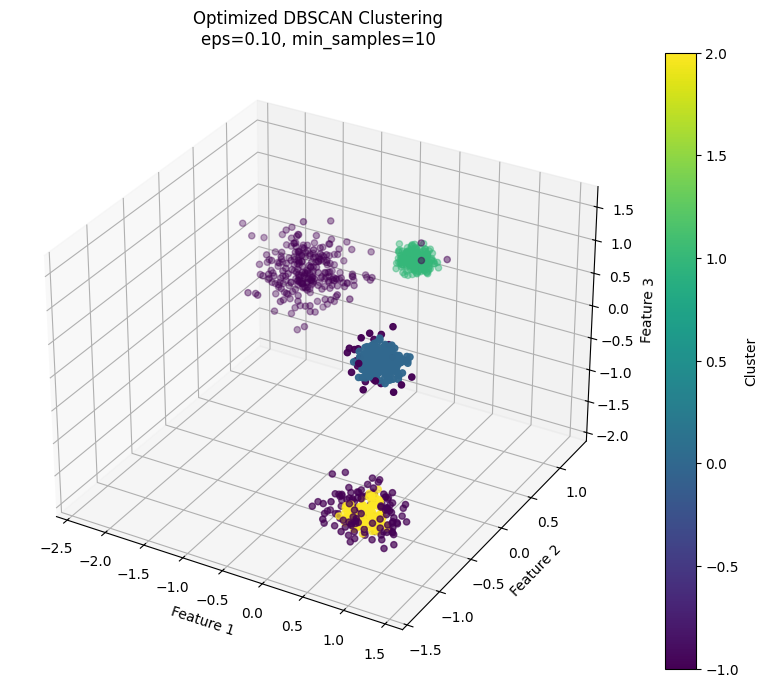

In [28]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

import numpy as np
import matplotlib.pyplot as plt


# 1. Generate 3D data
X_3d, _ = make_blobs(
    n_samples = 1000,
    n_features = 3,
    centers = 4,
    cluster_std = [0.5, 1.0, 1.5, 0.7],
    random_state = 42
)


# 2. Scale the data
scaler = StandardScaler()
X_3d_scaled = scaler.fit_transform(X_3d)


# 3. Parameter Grid Search
eps_values = np.arange(0.1, 1.1, 0.1)
min_samples_values = range(2, 11)

best_score = -1
best_eps = None
best_min_samples = None
best_labels = None


for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_3d_scaled)

        # Exclude noise points (-1)
        mask = labels != -1

        X_no_noise = X_3d_scaled[mask]
        labels_no_noise = labels[mask]

        # Silhouette score requires at least 2 clusters
        if len(set(labels_no_noise)) > 1:

            score = silhouette_score(
                X_no_noise,
                labels_no_noise
            )

            if score > best_score:
                best_score = score
                best_eps = eps
                best_min_samples = min_samples
                best_labels = labels.copy()


# 4. Print best parameters
print(f"Best eps: {best_eps:.2f}")
print(f"Best min_samples: {best_min_samples}")
print(f"Best Silhouette Score: {best_score:.4f}")


# 5. 3D Visualization
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    X_3d_scaled[:, 0],
    X_3d_scaled[:, 1],
    X_3d_scaled[:, 2],
    c=best_labels,
    cmap="viridis"
)

ax.set_title(
    f"Optimized DBSCAN Clustering\n"
    f"eps={best_eps:.2f}, min_samples={best_min_samples}"
)

ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_zlabel("Feature 3")

plt.colorbar(scatter, label="Cluster")
plt.show()